# Jupyter Notebook for Exploratory Data Analysis

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


In [4]:
df = pd.read_parquet("../data_pipeline/data/processed/season_12325_clean.parquet")
print(df.head())

                      seasonGoals_overall  seasonConceded_overall  \
name                                                                
Arsenal FC                             69                      34   
Tottenham Hotspur FC                   64                      65   
Manchester City FC                     72                      44   
Leicester City FC                      33                      80   
Crystal Palace FC                      51                      51   

                      seasonGoalsTotal_overall  seasonScoredNum_overall  \
name                                                                      
Arsenal FC                                 103                       69   
Tottenham Hotspur FC                       129                       64   
Manchester City FC                         116                       72   
Leicester City FC                          113                       33   
Crystal Palace FC                          102                    

## Checking for missing/ incomplete data

In [5]:
missing = df.isnull().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)
print(missing_cols)

Series([], dtype: int64)


## Descriptive Statistics

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
seasonGoals_overall,20.0,55.75,14.707231,26.0,45.50,58.0,66.00,86.0
seasonConceded_overall,20.0,55.75,14.421749,34.0,45.50,52.5,62.75,86.0
seasonGoalsTotal_overall,20.0,111.50,10.831241,86.0,104.00,110.5,119.25,129.0
seasonScoredNum_overall,20.0,55.75,14.707231,26.0,45.50,58.0,66.00,86.0
seasonConcededNum_overall,20.0,55.75,14.421749,34.0,45.50,52.5,62.75,86.0
...,...,...,...,...,...,...,...,...
additional_info.freekicks_total_over265_overall,20.0,31.30,19.876196,0.0,20.00,28.0,41.00,71.0
additional_info.freekicks_total_over275_overall,20.0,27.90,19.633216,0.0,16.25,28.0,35.50,71.0
additional_info.freekicks_total_over285_overall,20.0,21.50,14.827073,0.0,13.75,20.5,25.50,56.0
additional_info.freekicks_total_over295_overall,20.0,17.10,11.561734,0.0,7.75,19.0,22.25,43.0


## Variance and Correlation Check (Needs Revision and further analysis)

In [7]:
# Low variance columns are not useful for PCA or clustering
low_variance = df.var().sort_values()
print("Low variance features:\n", low_variance.head())

# Correlation matrix (optional: subset of top features to keep it readable)
corr = df.corr()
print(corr.shape)

# If you want to see the strongest relationships:
top_corr = corr.unstack().sort_values(ascending=False)
top_corr = top_corr[top_corr != 1]  # drop self-correlations
top_corr.head(10)


Low variance features:
 additional_info.penalties_recorded_matches_overall    0.0
cornersRecorded_matches_overall                       0.0
over85CardsPercentage_overall                         0.0
over75CardsPercentage_overall                         0.0
over75Cards_overall                                   0.0
dtype: float64
(543, 543)


over65CardsFor_overall            over65CardsForPercentage_overall    1.000000
over65CardsForPercentage_overall  over65CardsFor_overall              1.000000
dangerous_attacks_avg_overall     dangerous_attacks_num_overall       1.000000
dangerous_attacks_num_overall     dangerous_attacks_avg_overall       1.000000
attacks_avg_overall               attacks_num_overall                 1.000000
attacks_num_overall               attacks_avg_overall                 1.000000
shotsTotal_overall                shotsAVG_overall                    0.999999
shotsAVG_overall                  shotsTotal_overall                  0.999999
foulsAVG_overall                  foulsTotal_overall                  0.999998
foulsTotal_overall                foulsAVG_overall                    0.999998
dtype: float64

## Quick Visualizations 

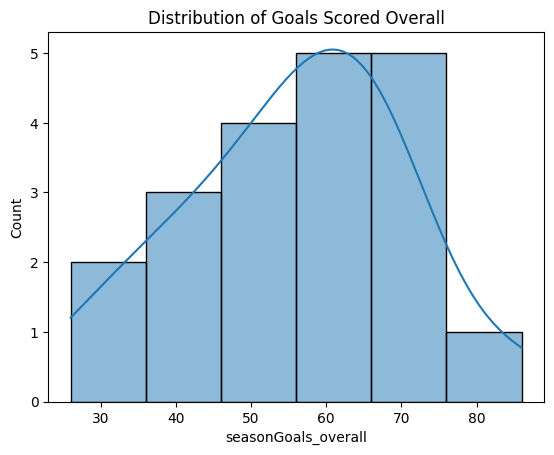

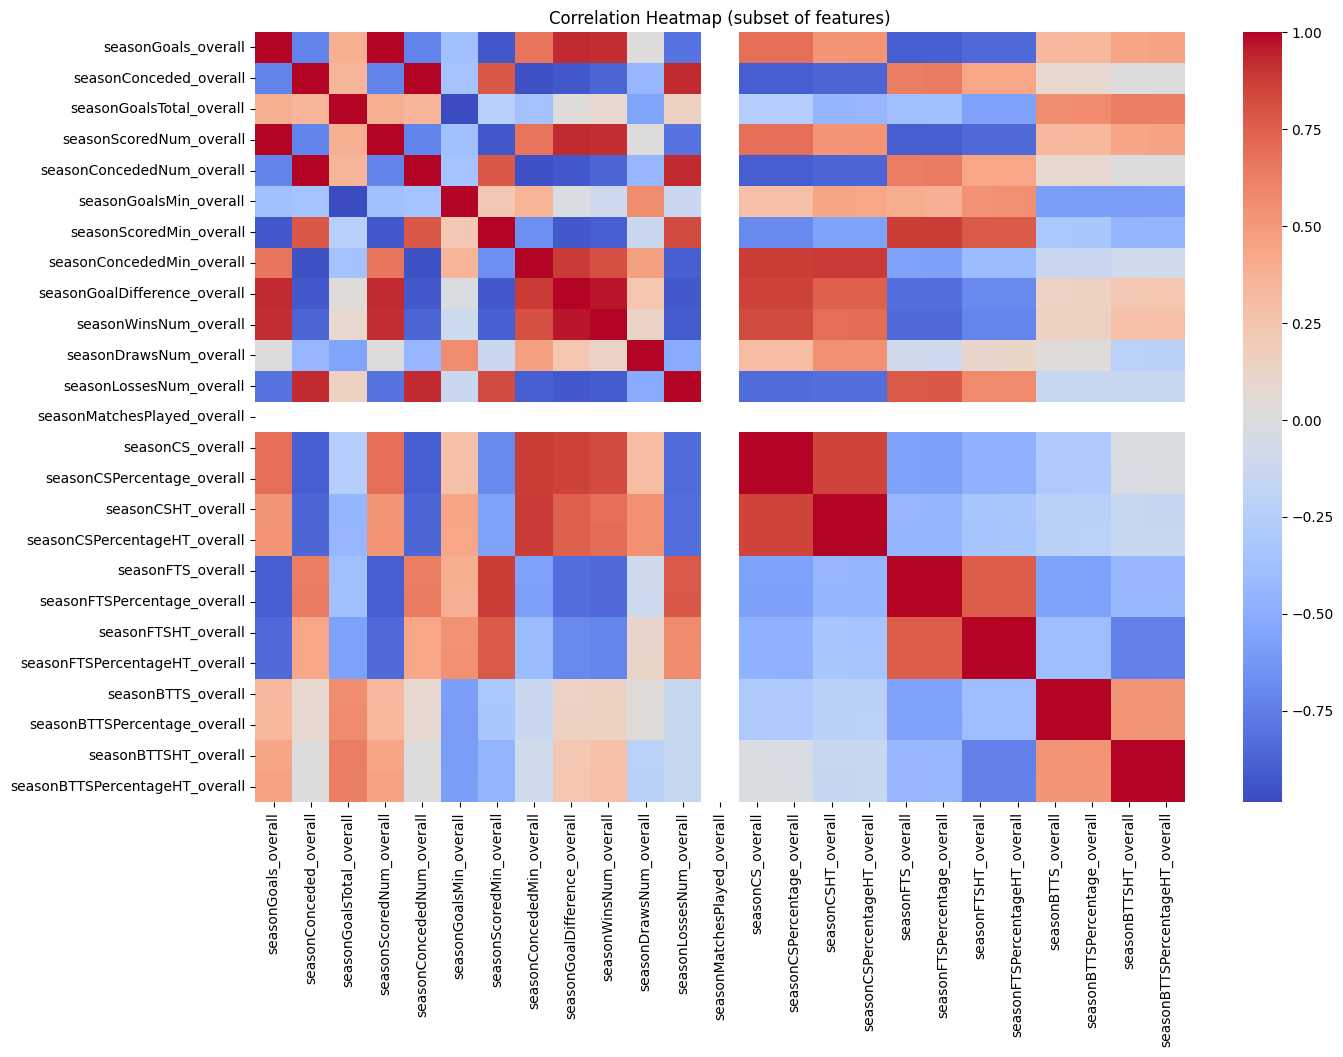

In [9]:
# Distribution of a key stat
sns.histplot(df['seasonGoals_overall'], kde=True)
plt.title("Distribution of Goals Scored Overall")
plt.show()

# Correlation heatmap (subset to avoid overcrowding)
subset_cols = df.columns[:25]  # or pick interesting ones manually
plt.figure(figsize=(15,10))
sns.heatmap(df[subset_cols].corr(), cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap (subset of features)")
plt.show()


## Feature Importance

In [10]:
target = 'seasonGoals_overall'
correlations = df.corr()[target].sort_values(ascending=False)
print(correlations.head(15))


seasonGoals_overall                                     1.000000
seasonScoredNum_overall                                 1.000000
seasonScoredAVG_overall                                 0.999965
seasonGoalDifference_overall                            0.929794
additional_info.seasonScoredOver15Percentage_overall    0.918142
winPercentage_overall                                   0.917819
additional_info.seasonScoredOver15Num_overall           0.917759
seasonWinsNum_overall                                   0.917398
additional_info.seasonScoredOver05Num_overall           0.901642
additional_info.seasonScoredOver05Percentage_overall    0.901539
leadingAtHT_overall                                     0.900885
leadingAtHTPercentage_overall                           0.899470
scoredBothHalves_overall                                0.897182
scoredBothHalvesPercentage_overall                      0.896913
gd_2hg_overall                                          0.894762
Name: seasonGoals_overall

## Feature Scaling

In [12]:
scaler = StandardScaler()
scaled = scaler.fit_transform(df)

# Convert back to a DataFrame (optional but nice)
df_scaled = pd.DataFrame(scaled, index=df.index, columns=df.columns)

print(df_scaled.head())


                      seasonGoals_overall  seasonConceded_overall  \
name                                                                
Arsenal FC                       0.924322               -1.547318   
Tottenham Hotspur FC             0.575521                0.658055   
Manchester City FC               1.133602               -0.835907   
Leicester City FC               -1.587043                1.725170   
Crystal Palace FC               -0.331361               -0.337920   

                      seasonGoalsTotal_overall  seasonScoredNum_overall  \
name                                                                      
Arsenal FC                           -0.805154                 0.924322   
Tottenham Hotspur FC                  1.657670                 0.575521   
Manchester City FC                    0.426258                 1.133602   
Leicester City FC                     0.142086                -1.587043   
Crystal Palace FC                    -0.899878                -0.3